In [1]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

# from data.manager import DBManager
# from config import DB_INFO

# manager = DBManager(DB_INFO)

In [7]:
def get_table_df(table_name):
    data = manager.get_close_data(table_name)
    return pd.DataFrame(data, columns=['timestamp', 'close'])

# get data from database
btc_usdt = get_table_df('binance_btc_usdt')
btc_usdt_f = get_table_df('binance_btc_usdt_f')
eth_usdt = get_table_df('binance_eth_usdt')
eth_usdt_f = get_table_df('binance_eth_usdt_f')

In [2]:
# or from local path
btc_usdt = pd.read_csv("binance_1m_BTCUSDT.csv").iloc[:, 2:4]
btc_usdt_f = pd.read_csv("binance_1m_BTCUSDT_f.csv").iloc[:, 1:3]
eth_usdt = pd.read_csv("binance_1m_ETHUSDT.csv").iloc[:, 2:4]
eth_usdt_f = pd.read_csv("binance_1m_ETHUSDT_f.csv").iloc[:, 1:3]

## Correlation between spot and future 

In [4]:
btc_usdt.columns = ['timestamp', 'btc_usdt_spot']
btc_usdt_f.columns = ['timestamp', 'btc_usdt_future']

btc_df = btc_usdt.merge(btc_usdt_f, how='outer', on='timestamp')
btc_df[btc_df.isna().any(axis=1)].isna().sum(axis=0)  # btc_usdt_spot 데이터만 없음. 받을 때 future를 늦게 받아서 그럼. 그냥 드랍

timestamp             0
btc_usdt_spot      2657
btc_usdt_future       0
dtype: int64

### Autocorrelation of 2 assets

In [49]:
btc_df1 = btc_df.dropna()
btc_df1.set_index("timestamp", inplace=True)
btc_df1.index = pd.to_datetime(btc_df1.index / 1000, unit='s')

btc_rtn_raw = btc_df1.pct_change(fill_method=None).dropna()
btc_rtn_log = (np.log(btc_df1) - np.log(btc_df1.shift(1))).dropna()

def get_autocorr(df, lag=1):
    auto_corr = [pearsonr(df[col].iloc[lag:], df.shift(lag)[col].iloc[lag:])for col in df.columns]
    return auto_corr

def get_autocorr_df(close_df, maxlag=10):
    rtn_df = (np.log(close_df) - np.log(close_df.shift(1))).dropna()
    auto_corrs = []
    for i in range(1, maxlag+1):
        acorr = get_autocorr(rtn_df, lag=i)
        auto_corrs.append([xx for x in acorr for xx in x])

    columns = pd.MultiIndex.from_tuples([('SPOT', 'autocorr'), ('SPOT', 'pvalue'), 
                                                      ('FUTURE', 'autocorr'), ('FUTURE', 'pvalue')])
    auto_corr_df = pd.DataFrame(auto_corrs, index=range(1, maxlag+1), columns=columns).round(4)
    return auto_corr_df

In [50]:
btc_autocorr = get_autocorr_df(btc_df1)
btc_autocorr

SPOT           FUTURE       
   autocorr  pvalue autocorr pvalue
1    0.0094  0.0000  -0.0072    0.0
2   -0.0202  0.0000  -0.0233    0.0
3   -0.0057  0.0000  -0.0079    0.0
4   -0.0064  0.0000  -0.0064    0.0
5   -0.0037  0.0000  -0.0032    0.0
6   -0.0090  0.0000  -0.0063    0.0
7   -0.0103  0.0000  -0.0092    0.0
8   -0.0016  0.0101  -0.0031    0.0
9   -0.0076  0.0000  -0.0075    0.0
10   0.0025  0.0001   0.0046    0.0

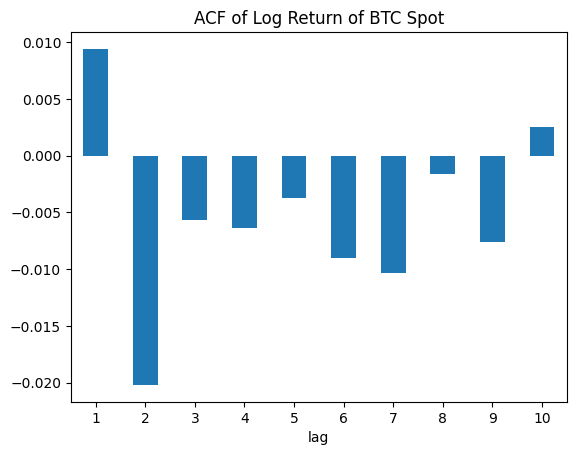

In [64]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
btc_autocorr['SPOT']['autocorr'].plot(kind='bar', ax=ax)
ax.set_title("ACF of Log Return of BTC Spot")
ax.set_xlabel("lag")
ax.set_xticklabels(range(1, 11), rotation=0)
plt.show()

what if interval is 5-min?

In [29]:
btc_df1_5m = btc_df1.resample("5min").last()

def print_autocorrs(close_df):
    rtn_df = (np.log(close_df) - np.log(close_df.shift(1))).dropna()
    for i in range(1, 10):
        acorr = get_autocorr(rtn_df, lag=i)
        print(f"AutoCorr of Lag {i} | SPOT - CORR: {acorr[0][0]:.4f} / P-value: {acorr[0][1]:.2f} | FUTURE - CORR: {acorr[1][0]:.4f} / P-value: {acorr[1][1]:.2f}")

get_autocorr_df(btc_df1_5m)

,autocorr,pvalue,autocorr,pvalue
1,-0.0179,0.0000,-0.0223,0.0000
2,-0.0075,0.0000,-0.0062,0.0000
3,0.0010,0.4791,0.0013,0.3488
4,-0.0095,0.0000,-0.0098,0.0000
5,-0.0144,0.0000,-0.0144,0.0000
6,-0.0122,0.0000,-0.0123,0.0000
7,0.0057,0.0001,0.0071,0.0000
8,-0.0025,0.0741,-0.0014,0.3273
9,-0.0006,0.6950,0.0017,0.2338
10,0.0019,0.1776,0.0018,0.1988


What if is 15-min? 30-min? and 1-h?

In [31]:
btc_df1_15 = btc_df1.resample("15min").last()
btc_df1_30 = btc_df1.resample("30min").last()
btc_df1_60 = btc_df1.resample("1h").last()

get_autocorr_df(btc_df1_15)

,autocorr,pvalue,autocorr,pvalue
1,0.0054,0.0285,0.0021,0.3924
2,-0.0338,0.0000,-0.0320,0.0000
3,-0.0003,0.8981,0.0033,0.1741
4,-0.0070,0.0042,-0.0074,0.0026
5,-0.0096,0.0001,-0.0115,0.0000
6,-0.0039,0.1141,-0.0040,0.0990
7,-0.0017,0.4997,0.0002,0.9359
8,-0.0040,0.1070,-0.0032,0.1882
9,-0.0019,0.4357,-0.0038,0.1206
10,0.0142,0.0000,0.0127,0.0000


In [32]:
get_autocorr_df(btc_df1_30)

,autocorr,pvalue,autocorr,pvalue
1,-0.0155,0.0000,-0.0150,0.0000
2,-0.0144,0.0000,-0.0132,0.0001
3,-0.0206,0.0000,-0.0207,0.0000
4,-0.0002,0.9490,0.0001,0.9718
5,0.0177,0.0000,0.0164,0.0000
6,0.0064,0.0631,0.0079,0.0228
7,-0.0141,0.0000,-0.0143,0.0000
8,-0.0209,0.0000,-0.0238,0.0000
9,0.0046,0.1814,0.0068,0.0488
10,-0.0056,0.1062,-0.0066,0.0580


In [33]:
get_autocorr_df(btc_df1_60)

,autocorr,pvalue,autocorr,pvalue
1,-0.0110,0.0251,-0.0041,0.4023
2,-0.0142,0.0037,-0.0165,0.0008
3,0.0017,0.7309,0.0014,0.7788
4,-0.0105,0.0317,-0.0095,0.0520
5,-0.0086,0.0781,-0.0092,0.0618
6,0.0011,0.8162,0.0004,0.9332
7,-0.0074,0.1337,-0.0090,0.0656
8,-0.0041,0.4046,-0.0037,0.4449
9,0.0051,0.3016,0.0042,0.3944
10,0.0094,0.0556,0.0077,0.1180


1m 을 제외하고,  
5m, 15m, 30m, 60m 에서 lag 1과 lag 2와의 음의 auto correlation 확인.  

In [34]:
eth_usdt.columns = ['timestamp', 'eth_usdt_spot']
eth_usdt_f.columns = ['timestamp', 'eth_usdt_future']
eth_df = eth_usdt.merge(eth_usdt_f, how='outer', on='timestamp')

eth_df1 = eth_df.dropna()
eth_df1.set_index("timestamp", inplace=True)
eth_df1.index = pd.to_datetime(eth_df1.index / 1000, unit='s')

for i in [1, 5, 15, 30, 60]:
    print(f"{i} minute Autocorrelation")
    if i == 1:
        print(get_autocorr_df(eth_df1))
    else:
        print(get_autocorr_df(eth_df1.resample(f"{i}min").last()))

    print('-' * 100) 

1 minute Autocorrelation
    autocorr  pvalue  autocorr  pvalue
1     0.0062  0.0000   -0.0039  0.0000
2    -0.0145  0.0000   -0.0244  0.0000
3    -0.0009  0.1742   -0.0065  0.0000
4    -0.0050  0.0000   -0.0147  0.0000
5    -0.0021  0.0009    0.0020  0.0012
6    -0.0085  0.0000   -0.0085  0.0000
7    -0.0113  0.0000   -0.0111  0.0000
8    -0.0050  0.0000   -0.0095  0.0000
9    -0.0045  0.0000   -0.0032  0.0000
10   -0.0002  0.7517    0.0014  0.0253
----------------------------------------------------------------------------------------------------
5 minute Autocorrelation
    autocorr  pvalue  autocorr  pvalue
1    -0.0176  0.0000   -0.0305  0.0000
2    -0.0069  0.0000   -0.0073  0.0000
3     0.0098  0.0000    0.0088  0.0000
4    -0.0048  0.0007    0.0001  0.9487
5    -0.0212  0.0000   -0.0204  0.0000
6    -0.0106  0.0000   -0.0146  0.0000
7     0.0056  0.0001    0.0122  0.0000
8    -0.0049  0.0005   -0.0051  0.0003
9     0.0041  0.0042    0.0054  0.0001
10   -0.0018  0.2012   -0.0048

BTC와 ETH 모두 time interval을 길게 할 수록 SPOT과 FUTURE 사이의 correlaiton 차이가 점점 작아지는 듯.  
그리고 공통적으로 lag 2, lag 3까지에서 음의 상관관계가 time interval마다 존재.  

BTC와 ETH를 비교해본다면 상관관계의 크기에는 크게 차이는 없는 듯 하나  
짧은 interval (1m, 5m) 에서 ETH에서의 SPOT / FUTURE correlation 차이가 좀 큰 듯 함. 

### Cross-correlation between 2 assets with lag

BTC, ETH에서 T기 SPOT에 대해 T-K, T-(K-1), ..., T-2, T-1, T, T+1, T+2, ..., T+(K-1), T+K 기의 lagged FUTURE 와의 corr을 살펴봄  

what about ETH future <- other asstes ?

In [66]:
def get_corr(Y, X, lag=6):
    temp_df = pd.merge(Y, X, left_index=True, right_index=True, how='inner')
    
    lag_arr = list(range(-lag, lag+1))
    corr_list = []
    for lag in lag_arr:
        temp_Y = temp_df.iloc[:lag, 0] if lag < 0 else temp_df.iloc[lag:, 0]
        temp_X = temp_df.shift(lag).iloc[:lag, 1] if lag < 0 else temp_df.shift(lag).iloc[lag:, 1]
        result = pearsonr(temp_Y, temp_X)
        corr_list.append([lag, result[0], result[1]])
        
    return pd.DataFrame(corr_list, columns=["lag", "corr", "pvalue"])

In [67]:
# 1min corr
eth_df1_rtn = (np.log(eth_df1) - np.log(eth_df1.shift(1))).dropna()
btc_df1_rtn = (np.log(btc_df1) - np.log(btc_df1.shift(1))).dropna()

ethf_eths = get_corr(eth_df1_rtn['eth_usdt_future'], eth_df1_rtn['eth_usdt_spot'])
ethf_btcs = get_corr(eth_df1_rtn['eth_usdt_future'], btc_df1_rtn['btc_usdt_spot'])
ethf_btcf = get_corr(eth_df1_rtn['eth_usdt_future'], btc_df1_rtn['btc_usdt_future'])

In [68]:
ethf_cross_corr = pd.concat([ethf_eths.set_index('lag'), ethf_btcs.set_index('lag'), ethf_btcf.set_index('lag')], axis=1)

new_columns = pd.MultiIndex.from_tuples([
    ('ETH_SPOT', 'corr'), ('ETH_SPOT', 'pvalue'),
    ('BTC_SPOT', 'corr'), ('BTC_SPOT', 'pvalue'),
    ('BTC_FUTRUE', 'corr'), ('BTC_FUTRUE', 'pvalue')
])

ethf_cross_corr.columns = new_columns
ethf_cross_corr.columns.name = "ETH_FUTURE"
ethf_cross_corr.round(3)

ETH_SPOT        BTC_SPOT        BTC_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6    -0.006  0.000   -0.008  0.000     -0.011  0.000
-5     0.001  0.339   -0.002  0.014      0.003  0.000
-4    -0.007  0.000   -0.008  0.000     -0.008  0.000
-3    -0.000  0.936   -0.002  0.003     -0.004  0.000
-2    -0.013  0.000   -0.014  0.000     -0.013  0.000
-1     0.010  0.000    0.019  0.000      0.005  0.000
 0     0.974  0.000    0.816  0.000      0.807  0.000
 1     0.003  0.000    0.012  0.000      0.015  0.000
 2    -0.017  0.000   -0.019  0.000     -0.017  0.000
 3    -0.005  0.000   -0.004  0.000     -0.007  0.000
 4    -0.010  0.000   -0.008  0.000     -0.007  0.000
 5     0.001  0.358    0.001  0.347     -0.000  0.946
 6    -0.012  0.000   -0.009  0.000     -0.007  0.000

In [69]:
# 함수화
def get_corr_table_ethf(eth_df, btc_df):
    # 1min corr
    eth_df_rtn = (np.log(eth_df) - np.log(eth_df.shift(1))).dropna()
    btc_df_rtn = (np.log(btc_df) - np.log(btc_df.shift(1))).dropna()

    ethf_eths = get_corr(eth_df_rtn['eth_usdt_future'], eth_df_rtn['eth_usdt_spot'])
    ethf_btcs = get_corr(eth_df_rtn['eth_usdt_future'], btc_df_rtn['btc_usdt_spot'])
    ethf_btcf = get_corr(eth_df_rtn['eth_usdt_future'], btc_df_rtn['btc_usdt_future'])
    
    ethf_cross_corr = pd.concat([ethf_eths.set_index('lag'), ethf_btcs.set_index('lag'), ethf_btcf.set_index('lag')], axis=1)

    new_columns = pd.MultiIndex.from_tuples([
        ('ETH_SPOT', 'corr'), ('ETH_SPOT', 'pvalue'),
        ('BTC_SPOT', 'corr'), ('BTC_SPOT', 'pvalue'),
        ('BTC_FUTRUE', 'corr'), ('BTC_FUTRUE', 'pvalue')
    ])

    ethf_cross_corr.columns = new_columns
    ethf_cross_corr.columns.name = "ETH_FUTURE"
    ethf_cross_corr = ethf_cross_corr.round(3)
    return ethf_cross_corr

def get_corr_table_btcf(eth_df, btc_df):
    # 1min corr
    eth_df_rtn = (np.log(eth_df) - np.log(eth_df.shift(1))).dropna()
    btc_df_rtn = (np.log(btc_df) - np.log(btc_df.shift(1))).dropna()

    btcf_eths = get_corr(btc_df_rtn['btc_usdt_future'], btc_df_rtn['btc_usdt_spot'])
    btcf_btcs = get_corr(btc_df_rtn['btc_usdt_future'], eth_df_rtn['eth_usdt_spot'])
    btcf_btcf = get_corr(btc_df_rtn['btc_usdt_future'], eth_df_rtn['eth_usdt_future'])
    
    btcf_cross_corr = pd.concat([btcf_eths.set_index('lag'), btcf_btcs.set_index('lag'), btcf_btcf.set_index('lag')], axis=1)

    new_columns = pd.MultiIndex.from_tuples([
        ('BTC_SPOT', 'corr'), ('BTC_SPOT', 'pvalue'),
        ('ETH_SPOT', 'corr'), ('ETH_SPOT', 'pvalue'),
        ('ETH_FUTRUE', 'corr'), ('ETH_FUTRUE', 'pvalue')
    ])

    btcf_cross_corr.columns = new_columns
    btcf_cross_corr.columns.name = "ETH_FUTURE"
    btcf_cross_corr = btcf_cross_corr.round(3)
    return btcf_cross_corr

In [70]:
btc_df1_5m = btc_df1.resample("5min").last()
btc_df1_15m = btc_df1.resample("15min").last()
btc_df1_30m = btc_df1.resample("30min").last()
btc_df1_60m = btc_df1.resample("1h").last()

eth_df1_5m = eth_df1.resample("5min").last()
eth_df1_15m = eth_df1.resample("15min").last()
eth_df1_30m = eth_df1.resample("30min").last()
eth_df1_60m = eth_df1.resample("1h").last()

In [32]:
# 5-min
get_corr_table_ethf(eth_df1_5m ,btc_df1_5m)

ETH_SPOT        BTC_SPOT        BTC_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6    -0.011  0.000   -0.011  0.000     -0.011  0.000
-5    -0.022  0.000   -0.016  0.000     -0.015  0.000
-4    -0.002  0.134   -0.004  0.007     -0.005  0.001
-3     0.007  0.000    0.005  0.001      0.007  0.000
-2    -0.006  0.000   -0.006  0.000     -0.004  0.006
-1    -0.018  0.000   -0.015  0.000     -0.017  0.000
 0     0.994  0.000    0.842  0.000      0.839  0.000
 1    -0.025  0.000   -0.018  0.000     -0.017  0.000
 2    -0.010  0.000   -0.004  0.005     -0.004  0.003
 3     0.013  0.000    0.008  0.000      0.006  0.000
 4    -0.005  0.001   -0.006  0.000     -0.005  0.001
 5    -0.019  0.000   -0.019  0.000     -0.019  0.000
 6    -0.015  0.000   -0.015  0.000     -0.015  0.000

In [34]:
# 15-min
get_corr_table_ethf(eth_df1_15m ,btc_df1_15m)

ETH_SPOT        BTC_SPOT        BTC_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6    -0.005  0.042   -0.003  0.231     -0.003  0.239
-5    -0.010  0.000   -0.012  0.000     -0.013  0.000
-4     0.001  0.677   -0.002  0.384     -0.001  0.704
-3     0.002  0.375    0.001  0.573      0.004  0.113
-2    -0.037  0.000   -0.032  0.000     -0.031  0.000
-1     0.012  0.000    0.010  0.000      0.011  0.000
 0     0.996  0.000    0.849  0.000      0.846  0.000
 1     0.016  0.000    0.017  0.000      0.016  0.000
 2    -0.034  0.000   -0.040  0.000     -0.041  0.000
 3     0.003  0.292    0.005  0.054      0.006  0.016
 4     0.000  0.874   -0.004  0.117     -0.005  0.064
 5    -0.013  0.000   -0.009  0.000     -0.009  0.000
 6    -0.002  0.309   -0.006  0.023     -0.007  0.007

In [35]:
# 30-min
get_corr_table_ethf(eth_df1_30m ,btc_df1_30m)

ETH_SPOT        BTC_SPOT        BTC_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6    -0.002  0.481   -0.000  0.922      0.001  0.774
-5     0.008  0.014    0.018  0.000      0.017  0.000
-4     0.001  0.723    0.002  0.650      0.002  0.545
-3    -0.017  0.000   -0.018  0.000     -0.018  0.000
-2    -0.005  0.170   -0.008  0.021     -0.005  0.126
-1    -0.019  0.000   -0.011  0.001     -0.008  0.019
 0     0.996  0.000    0.853  0.000      0.852  0.000
 1    -0.013  0.000   -0.021  0.000     -0.023  0.000
 2    -0.006  0.066   -0.009  0.012     -0.010  0.004
 3    -0.018  0.000   -0.021  0.000     -0.021  0.000
 4     0.001  0.824    0.001  0.874      0.001  0.763
 5     0.011  0.002    0.008  0.023      0.008  0.030
 6    -0.003  0.339    0.004  0.213      0.003  0.333

In [36]:
# 60-min
get_corr_table_ethf(eth_df1_60m ,btc_df1_60m)

ETH_SPOT        BTC_SPOT        BTC_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6     0.016  0.001    0.002  0.630      0.002  0.622
-5    -0.015  0.002   -0.009  0.056     -0.010  0.047
-4    -0.013  0.007   -0.007  0.141     -0.007  0.163
-3    -0.006  0.195   -0.001  0.900     -0.000  0.939
-2    -0.020  0.000   -0.013  0.007     -0.014  0.006
-1    -0.002  0.634    0.000  0.945      0.007  0.136
 0     0.999  0.000    0.848  0.000      0.847  0.000
 1    -0.001  0.852   -0.009  0.063     -0.010  0.048
 2    -0.020  0.000   -0.021  0.000     -0.022  0.000
 3    -0.006  0.218   -0.003  0.584     -0.004  0.464
 4    -0.014  0.006   -0.015  0.002     -0.014  0.004
 5    -0.015  0.002   -0.015  0.003     -0.015  0.002
 6     0.014  0.003    0.009  0.083      0.008  0.111

what about BTC Future <- other assets ?

In [71]:
# 1m
get_corr_table_btcf(eth_df1 ,btc_df1)

BTC_SPOT        ETH_SPOT        ETH_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6    -0.007  0.000   -0.005  0.000     -0.007  0.000
-5    -0.003  0.000   -0.003  0.000     -0.000  0.946
-4    -0.007  0.000   -0.003  0.000     -0.007  0.000
-3    -0.006  0.000   -0.001  0.065     -0.007  0.000
-2    -0.020  0.000   -0.016  0.000     -0.017  0.000
-1     0.018  0.000    0.019  0.000      0.015  0.000
 0     0.985  0.000    0.821  0.000      0.807  0.000
 1    -0.004  0.000    0.004  0.000      0.005  0.000
 2    -0.023  0.000   -0.015  0.000     -0.013  0.000
 3    -0.006  0.000   -0.004  0.000     -0.004  0.000
 4    -0.007  0.000   -0.008  0.000     -0.008  0.000
 5    -0.002  0.003   -0.000  0.900      0.003  0.000
 6    -0.009  0.000   -0.009  0.000     -0.011  0.000

In [42]:
# 5m
get_corr_table_btcf(eth_df1_5m ,btc_df1_5m)

BTC_SPOT        ETH_SPOT        ETH_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6    -0.012  0.000   -0.013  0.000     -0.015  0.000
-5    -0.014  0.000   -0.020  0.000     -0.019  0.000
-4    -0.010  0.000   -0.008  0.000     -0.005  0.001
-3     0.000  0.881    0.005  0.000      0.006  0.000
-2    -0.008  0.000   -0.004  0.012     -0.004  0.003
-1    -0.016  0.000   -0.009  0.000     -0.017  0.000
 0     0.995  0.000    0.839  0.000      0.839  0.000
 1    -0.021  0.000   -0.016  0.000     -0.017  0.000
 2    -0.005  0.001   -0.005  0.000     -0.004  0.006
 3     0.003  0.073    0.009  0.000      0.007  0.000
 4    -0.010  0.000   -0.006  0.000     -0.005  0.001
 5    -0.015  0.000   -0.015  0.000     -0.015  0.000
 6    -0.012  0.000   -0.011  0.000     -0.011  0.000

In [44]:
# 15m
get_corr_table_btcf(eth_df1_15m ,btc_df1_15m)

BTC_SPOT        ETH_SPOT        ETH_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6    -0.005  0.059   -0.006  0.012     -0.007  0.007
-5    -0.009  0.000   -0.008  0.002     -0.009  0.000
-4    -0.008  0.001   -0.003  0.180     -0.005  0.064
-3     0.001  0.791    0.005  0.031      0.006  0.016
-2    -0.034  0.000   -0.043  0.000     -0.041  0.000
-1     0.004  0.085    0.014  0.000      0.016  0.000
 0     0.997  0.000    0.844  0.000      0.846  0.000
 1     0.005  0.033    0.014  0.000      0.011  0.000
 2    -0.031  0.000   -0.030  0.000     -0.031  0.000
 3     0.002  0.424    0.003  0.199      0.004  0.113
 4    -0.006  0.021   -0.001  0.579     -0.001  0.704
 5    -0.011  0.000   -0.013  0.000     -0.013  0.000
 6    -0.003  0.154    0.000  0.975     -0.003  0.239

In [45]:
# 30m
get_corr_table_btcf(eth_df1_30m ,btc_df1_30m)

BTC_SPOT        ETH_SPOT        ETH_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6     0.006  0.082    0.003  0.402      0.003  0.333
-5     0.018  0.000    0.008  0.027      0.008  0.030
-4    -0.000  0.962    0.000  0.967      0.001  0.763
-3    -0.020  0.000   -0.019  0.000     -0.021  0.000
-2    -0.016  0.000   -0.009  0.012     -0.010  0.004
-1    -0.017  0.000   -0.025  0.000     -0.023  0.000
 0     0.998  0.000    0.850  0.000      0.852  0.000
 1    -0.012  0.000   -0.005  0.114     -0.008  0.019
 2    -0.012  0.001   -0.007  0.053     -0.005  0.126
 3    -0.022  0.000   -0.017  0.000     -0.018  0.000
 4     0.000  0.983   -0.000  0.906      0.002  0.545
 5     0.017  0.000    0.019  0.000      0.017  0.000
 6     0.008  0.016    0.000  0.896      0.001  0.774

In [46]:
# 60m
get_corr_table_btcf(eth_df1_60m ,btc_df1_60m)

BTC_SPOT        ETH_SPOT        ETH_FUTRUE       
        corr pvalue     corr pvalue       corr pvalue
lag                                                  
-6     0.001  0.877    0.008  0.088      0.008  0.111
-5    -0.009  0.073   -0.015  0.002     -0.015  0.002
-4    -0.010  0.042   -0.014  0.004     -0.014  0.004
-3     0.001  0.802   -0.004  0.439     -0.004  0.464
-2    -0.015  0.002   -0.022  0.000     -0.022  0.000
-1    -0.011  0.028   -0.009  0.059     -0.010  0.048
 0     0.999  0.000    0.846  0.000      0.847  0.000
 1    -0.004  0.453    0.008  0.112      0.007  0.136
 2    -0.015  0.002   -0.014  0.005     -0.014  0.006
 3     0.002  0.702   -0.000  0.939     -0.000  0.939
 4    -0.010  0.041   -0.007  0.165     -0.007  0.163
 5    -0.009  0.066   -0.009  0.063     -0.010  0.047
 6     0.001  0.856    0.002  0.759      0.002  0.622

여기까지 살펴본 결과,  
5min 에서의 future - spot 간의 lead-lag relationship은 거의 없는 것으로 확인.  
(=lag 0의 correlation이 압도적으로 높음(0.99) -> 정보가 매우 빠르게 반영.)

Chan의 논문과 달리 lead-lag relationship이 없는 이유는 아래 두가지로 정리됨  
1. (Chan, 1992) 이후로 기술의 대중화로 시장참여자가 정보를 얻기가 쉬워짐으로써 정보의 반영 시차가 거의 없어짐
2. BTC, ETH 등 단일 자산에 대해 lead-lag를 살펴봤기에 index 보다 future - spot 간의 반영 시차가 생기기 어려움  
    -> Index와 future간의 차이는 정보반영 뿐 아니라 거래 유동성에도 기인하기 때문  

따라서 이후 진행방향은?  
- 가상자산에 대한 시계열 데이터로의 lead-lag 대신 대체데이터를 통한 lead-lag 판별
- 미국, 중국, 한국, 일본 등 나라의 Equity index와 index future 데이터를 구하기 